all 36 runs change exactly what their name says


,children,MAE,MAE_min,MAE_max,balanced,balanced_min,balanced_max,frozen_MAE,frozen_balanced
variant,,,,,,,,,
frozen model,103,0.60,0.59,0.60,0.88,0.87,0.89,0.60,0.88
no batch norm after the fc layer,103,1.50,0.70,2.96,2.30,1.11,4.39,0.60,0.88
N2 part only (5-15 min),103,0.62,0.61,0.62,0.91,0.90,0.92,0.60,0.88
pre-N2 part only (0-5 min),103,0.63,0.62,0.64,0.91,0.88,0.93,0.60,0.88
children under 6 only,80,0.46,0.46,0.46,0.57,0.57,0.57,0.36,0.44
8 s windows,103,0.63,0.62,0.64,0.95,0.93,0.97,0.60,0.88
32 s windows,103,0.60,0.58,0.62,0.88,0.86,0.93,0.60,0.88
MSE loss on log(age),103,0.60,0.58,0.61,0.88,0.84,0.90,0.60,0.88
MSE loss on age in years,103,0.62,0.61,0.62,0.83,0.82,0.84,0.60,0.88


variant minus frozen model, in years (negative = variant better)


observed   2.5%  97.5%  \
variant                          metric                                 
no batch norm after the fc layer MAE              0.897  0.795  0.997   
                                 balanced MAE     1.415  1.230  1.599   
N2 part only (5-15 min)          MAE              0.021 -0.019  0.062   
                                 balanced MAE     0.027 -0.032  0.087   
pre-N2 part only (0-5 min)       MAE              0.029 -0.078  0.152   
                                 balanced MAE     0.024 -0.125  0.192   
children under 6 only            MAE              0.092  0.020  0.171   
                                 balanced MAE     0.134  0.032  0.247   
8 s windows                      MAE              0.036  0.012  0.060   
                                 balanced MAE     0.065  0.030  0.101   
32 s windows                     MAE             -0.003 -0.029  0.023   
                                 balanced MAE     0.001 -0.055  0.053   
MSE loss on log(age)             MAE              0.005 -0.010  0.019   
                                 balanced MAE    -0.004 -0.034  0.026   
MSE loss on age in years         MAE              0.018 -0.047  0.089   
                                 balanced MAE    -0.052 -0.155  0.056   
learning rate 3e-4               MAE              0.039  0.019  0.059   
                                 balanced MAE     0.055  0.029  0.081   
learning rate 3e-3               MAE             -0.016 -0.043  0.014   
                                 balanced MAE    -0.018 -0.070  0.040   
no dropout or weight decay       MAE              0.017 -0.027  0.060   
                                 balanced MAE     0.034 -0.032  0.097   

                                               share variant worse  clear  
variant                          metric                                    
no batch norm after the fc layer MAE                         1.000   True  
                                 balanced MAE                1.000   True  
N2 part only (5-15 min)          MAE                         0.851  False  
                                 balanced MAE                0.818  False  
pre-N2 part only (0-5 min)       MAE                         0.684  False  
                                 balanced MAE                0.603  False  
children under 6 only            MAE                         0.992   True  
                                 balanced MAE                0.994   True  
8 s windows                      MAE                         0.999   True  
                                 balanced MAE                1.000   True  
32 s windows                     MAE                         0.415  False  
                                 balanced MAE                0.518  False  
MSE loss on log(age)             MAE                         0.732  False  
                                 balanced MAE                0.402  False  
MSE loss on age in years         MAE                         0.695  False  
                                 balanced MAE                0.169  False  
learning rate 3e-4               MAE                         1.000   True  
                                 balanced MAE                1.000   True  
learning rate 3e-3               MAE                         0.142  False  
                                 balanced MAE                0.258  False  
no dropout or weight decay       MAE                         0.778  False  
                                 balanced MAE                0.848  False

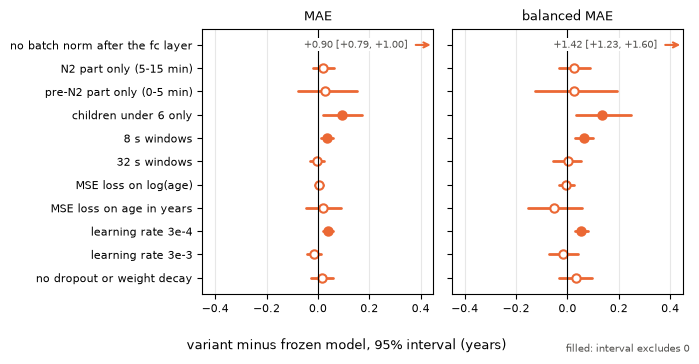

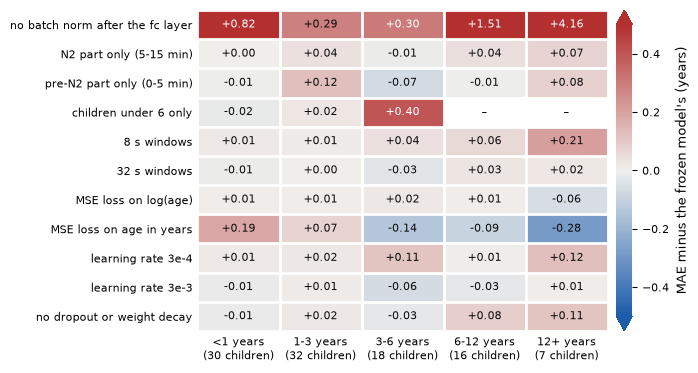

,last_MAE,best_MAE,optimism,best_epochs
variant,,,,
frozen model,0.598,0.595,0.003,"50, 52, 50"
no batch norm after the fc layer,1.495,1.424,0.072,"36, 1, 39"
N2 part only (5-15 min),0.619,0.612,0.008,"56, 54, 54"
pre-N2 part only (0-5 min),0.627,0.623,0.005,"52, 55, 51"
children under 6 only,0.457,0.431,0.026,"46, 30, 35"
8 s windows,0.634,0.621,0.013,"34, 44, 38"
32 s windows,0.595,0.582,0.013,"50, 52, 54"
MSE loss on log(age),0.603,0.597,0.005,"50, 57, 50"
MSE loss on age in years,0.616,0.608,0.008,"47, 56, 48"


,variant,seed,alive features (of 64),SD of predictions (years),SD of true ages (years),val MAE
0,frozen model,0,64,3.72,3.99,0.60
1,frozen model,1,64,3.80,3.99,0.60
2,frozen model,2,64,3.69,3.99,0.59
3,no batch norm after the fc layer,0,9,3.29,3.99,0.70
4,no batch norm after the fc layer,1,0,0.00,3.99,2.96
5,no batch norm after the fc layer,2,7,2.96,3.99,0.82


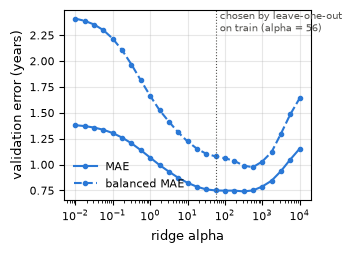

alpha 56: MAE 0.75; best MAE over the grid 0.74 at alpha 3.2e+02


In [1]:
# %% cell 1: setup
# AI-assisted: written with Claude Code on 17 Nov 2026 (see docs/AI_USAGE.md).
# Post-freeze experiments: one change at a time from the frozen CNN, 3 seeds each, scored on validation only.

import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import torch
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, str(Path("../scripts").resolve()))
from train_cnn import EDGES, GROUPS, BrainAgeCNN, load_split, eval_windows, window_log_ages, child_ages

DATA, OUT = Path("../data"), Path("../outputs")
FIG, TAB = OUT / "figures", OUT / "tables"
SEEDS = (0, 1, 2)
SEED_COLUMNS = [f"seed {s}" for s in SEEDS]

# each variant: its label, and the settings it changes; everything else is the frozen setting
VARIANTS = {
    "no_fc_bn":  ("no batch norm after the fc layer", {"fc_bn": False}),
    "n2":        ("N2 part only (5-15 min)", {"part": "N2"}),
    "preN2":     ("pre-N2 part only (0-5 min)", {"part": "preN2"}),
    "under6":    ("children under 6 only", {"max_age": 6.0}),
    "win8":      ("8 s windows", {"window_s": 8}),
    "win32":     ("32 s windows", {"window_s": 32}),
    "mse_log":   ("MSE loss on log(age)", {"loss": "mse"}),
    "mse_years": ("MSE loss on age in years", {"loss": "mse", "target": "years"}),
    "lr3e-4":    ("learning rate 3e-4", {"lr": 3e-4}),
    "lr3e-3":    ("learning rate 3e-3", {"lr": 3e-3}),
    "noreg":     ("no dropout or weight decay", {"dropout": 0.0, "weight_decay": 0.0}),
}
LABEL = {"frozen": "frozen model"} | {key: label for key, (label, _) in VARIANTS.items()}

# the frozen settings (docs/FROZEN_SETTINGS.md); the frozen checkpoints predate the last five keys
FROZEN = {"epochs": 60, "lr": 1e-3, "weight_decay": 1e-2, "dropout": 0.3, "crops_per_child": 8, "batch_size": 64,
          "overfit": False, "window_s": 16, "part": "all", "max_age": None, "fc_bn": True, "loss": "huber", "target": "log"}

def run_dir(key, seed):
    return OUT / (f"cnn16s_seed{seed}" if key == "frozen" else f"exp_{key}_seed{seed}")

COLOR = {"ridge": "#2a78d6", "CNN": "#eb6834"}   # the same colours as in 02
plt.rcParams.update({"font.size": 9, "axes.titlesize": 9, "axes.labelsize": 9,
                     "legend.fontsize": 8, "xtick.labelsize": 8, "ytick.labelsize": 8})

def save(fig, name):
    # sized for a 7-inch-wide page: 300 dpi PNG for Word, PDF for LaTeX
    fig.savefig(FIG / f"{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")

def scores(age, pred):
    # MAE and balanced MAE as in 01 and 02; age groups without children are left out of the balance
    err = pd.Series(np.abs(pred - age))
    per_group = err.groupby(pd.cut(age, EDGES, right=False, labels=GROUPS), observed=True).mean()
    return {"MAE": err.mean(), "balanced MAE": per_group.mean(), **per_group.to_dict()}

# %% cell 2: check every run, then load the predictions
# each run must differ from the frozen settings in exactly its own change (and its seed)
for key in LABEL:
    change = VARIANTS[key][1] if key in VARIANTS else {}
    for seed in SEEDS:
        saved = torch.load(run_dir(key, seed) / "final.pt", map_location="cpu", weights_only=True)["settings"]
        expected = FROZEN | change | {"seed": seed}
        assert set(saved) <= set(expected), f"{key} seed {seed}: unknown setting"
        actual = {k: saved.get(k, FROZEN.get(k)) for k in expected}
        assert actual == expected, f"{key} seed {seed}: settings {actual}"
print(f"all {len(LABEL) * len(SEEDS)} runs change exactly what their name says")

def load_val(key):
    # one row per child, one prediction column per seed, joined on id
    df = None
    for seed, column in zip(SEEDS, SEED_COLUMNS):
        p = pd.read_csv(run_dir(key, seed) / "val_predictions.csv", dtype={"id": str}).rename(columns={"pred": column})
        if df is None:
            df = p
            continue
        n = len(df)
        df = df.merge(p, on="id", validate="one_to_one", suffixes=("", "_seed"))
        assert len(df) == n == len(p), f"{key}: the seeds cover different children"
        assert np.allclose(df.age, df.age_seed), f"{key}: the seeds disagree on an age"
        df = df.drop(columns="age_seed")
    return df.set_index("id")

val = {key: load_val(key) for key in LABEL}
frozen = val["frozen"]
for key, df in val.items():
    children = frozen.index[frozen.age < 6] if key == "under6" else frozen.index
    assert sorted(df.index) == sorted(children), f"{key}: not the expected validation children"
    assert np.allclose(df.age, frozen.age[df.index]), f"{key}: an age differs from the frozen runs"
{key: len(df) for key, df in val.items()}

# %% cell 3: results per variant (mean and range over the 3 seeds)
rows = []
for key, df in val.items():
    age = df.age.to_numpy()
    ref = frozen.loc[df.index]   # the frozen runs on the same children (only differs for the under-6 variant)
    for seed, column in zip(SEEDS, SEED_COLUMNS):
        rows.append({"variant": key, "seed": seed, "children": len(df), **scores(age, df[column].to_numpy()),
                     **{f"frozen {m}": v for m, v in scores(age, ref[column].to_numpy()).items()
                        if m in ("MAE", "balanced MAE")}})
runs = pd.DataFrame(rows)
runs.to_csv(TAB / "experiments_runs_val.csv", index=False)

summary = runs.groupby("variant", sort=False).agg(
    children=("children", "first"),
    MAE=("MAE", "mean"), MAE_min=("MAE", "min"), MAE_max=("MAE", "max"),
    balanced=("balanced MAE", "mean"), balanced_min=("balanced MAE", "min"), balanced_max=("balanced MAE", "max"),
    frozen_MAE=("frozen MAE", "mean"), frozen_balanced=("frozen balanced MAE", "mean"),
    **{group: (group, "mean") for group in GROUPS})
summary.index = summary.index.map(LABEL)
summary.to_csv(TAB / "experiments_val.csv")
display(summary.drop(columns=GROUPS).round(2))

# %% cell 4: paired bootstrap, each variant against the frozen model on the same children
def paired_bootstrap(age, err_a, err_b, B=10_000, seed=0):
    # as in 02: children drawn with replacement within each age group, both models scored on the same draw.
    # Age groups without children (6-12 and 12+ for the under-6 variant) are left out.
    group = pd.cut(age, EDGES, right=False, labels=GROUPS).codes
    members = [m for m in (np.flatnonzero(group == g) for g in range(len(GROUPS))) if len(m)]
    rng = np.random.default_rng(seed)
    d_mae, d_bal = np.empty(B), np.empty(B)
    for b in range(B):
        draw = [rng.choice(m, size=len(m), replace=True) for m in members]
        drawn = np.concatenate(draw)
        d_mae[b] = err_a[drawn].mean() - err_b[drawn].mean()
        d_bal[b] = np.mean([err_a[d].mean() - err_b[d].mean() for d in draw])
    return d_mae, d_bal

def child_errors(df):
    # each child's error, averaged over the 3 seeds (as in 02)
    return np.abs(df[SEED_COLUMNS].to_numpy() - df.age.to_numpy()[:, None]).mean(axis=1)

def balanced(err, age):
    return pd.Series(err).groupby(pd.cut(age, EDGES, right=False, labels=GROUPS), observed=True).mean().mean()

rows = []
for key in VARIANTS:
    df = val[key]
    age = df.age.to_numpy()
    err_v, err_f = child_errors(df), child_errors(frozen.loc[df.index])
    d_mae, d_bal = paired_bootstrap(age, err_v, err_f)
    observed = {"MAE": err_v.mean() - err_f.mean(), "balanced MAE": balanced(err_v, age) - balanced(err_f, age)}
    # the same numbers as the table above: the mean over seeds minus the frozen mean over seeds
    s = summary.loc[LABEL[key]]
    assert np.isclose(observed["MAE"], s.MAE - s.frozen_MAE)
    assert np.isclose(observed["balanced MAE"], s.balanced - s.frozen_balanced)
    for metric, d in [("MAE", d_mae), ("balanced MAE", d_bal)]:
        low, high = np.percentile(d, [2.5, 97.5])
        rows.append({"variant": LABEL[key], "metric": metric, "observed": observed[metric],
                     "2.5%": low, "97.5%": high, "share variant worse": (d > 0).mean()})
boot = pd.DataFrame(rows).set_index(["variant", "metric"])
boot["clear"] = (boot["97.5%"] < 0) | (boot["2.5%"] > 0)   # the interval excludes 0
boot.to_csv(TAB / "experiments_bootstrap_val.csv")
print("variant minus frozen model, in years (negative = variant better)")
display(boot.round(3))

# %% cell 5: forest plot of the differences
XLIM = (-0.45, 0.45)
fig, axes = plt.subplots(1, 2, figsize=(7, 3.6), sharey=True)
labels = [LABEL[key] for key in VARIANTS]
y = np.arange(len(labels))[::-1]   # the first variant at the top
for ax, metric in zip(axes, ["MAE", "balanced MAE"]):
    b = boot.xs(metric, level="metric").loc[labels]
    for yi, (label, row) in zip(y, b.iterrows()):
        if row["2.5%"] > XLIM[1]:
            # the whole interval is off the scale: an arrow at the edge, and the numbers beside it
            ax.annotate("", xy=(XLIM[1], yi), xytext=(XLIM[1] - 0.08, yi),
                        arrowprops=dict(arrowstyle="->", color=COLOR["CNN"], linewidth=1.5))
            ax.text(XLIM[1] - 0.1, yi, f"{row.observed:+.2f} [{row['2.5%']:+.2f}, {row['97.5%']:+.2f}]",
                    ha="right", va="center", fontsize=7, color="#52514e",
                    bbox=dict(facecolor="white", edgecolor="none", pad=1))
            continue
        assert XLIM[0] <= row["2.5%"] and row["97.5%"] <= XLIM[1], f"{label}: widen XLIM"
        ax.plot([row["2.5%"], row["97.5%"]], [yi, yi], color=COLOR["CNN"], linewidth=2, solid_capstyle="round")
        ax.plot(row.observed, yi, marker="o", markersize=6, color=COLOR["CNN"],
                markerfacecolor=COLOR["CNN"] if row.clear else "white", markeredgewidth=1.5)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set(xlim=XLIM, title=metric)
    ax.grid(axis="x", alpha=0.3)
axes[0].set_yticks(y, labels)
axes[0].set_ylim(-0.7, len(labels) - 0.3)
fig.supxlabel("variant minus frozen model, 95% interval (years)", fontsize=9)
fig.text(0.99, 0.005, "filled: interval excludes 0", ha="right", va="bottom", fontsize=7, color="#52514e")
fig.tight_layout()
save(fig, "experiments_forest")
plt.show()

# %% cell 6: where each change helps or hurts, by age group
diff = pd.DataFrame({group: summary[group] - summary.loc["frozen model", group] for group in GROUPS})
diff = diff.drop(index="frozen model")
counts = frozen.age.groupby(pd.cut(frozen.age, EDGES, right=False, labels=GROUPS), observed=False).size()
diff.round(3).to_csv(TAB / "experiments_by_group_val.csv")

LIMIT = 0.5   # years; larger differences get the end colour, and their number shows the size
cmap = LinearSegmentedColormap.from_list("better_worse", ["#1c5cab", "#f0efec", "#b3302f"])
cmap.set_bad("white")
fig, ax = plt.subplots(figsize=(7, 3.8))
image = ax.imshow(np.ma.masked_invalid(diff.to_numpy()), cmap=cmap, vmin=-LIMIT, vmax=LIMIT, aspect="auto")
bar = fig.colorbar(image, ax=ax, fraction=0.04, pad=0.02, extend="both")
bar.set_label("MAE minus the frozen model's (years)")
bar.outline.set_visible(False)
for (i, j), v in np.ndenumerate(diff.to_numpy()):
    text = "–" if np.isnan(v) else f"{v:+.2f}"
    dark = not np.isnan(v) and abs(v) > 0.6 * LIMIT
    ax.text(j, i, text, ha="center", va="center", fontsize=8, color="white" if dark else "#0b0b0b")
ax.set_xticks(range(len(GROUPS)), [f"{g} years\n({counts[g]} children)" for g in GROUPS])
ax.set_yticks(range(len(diff)), diff.index)
ax.set_xticks(np.arange(len(GROUPS) + 1) - 0.5, minor=True)
ax.set_yticks(np.arange(len(diff) + 1) - 0.5, minor=True)
ax.tick_params(which="both", length=0)
ax.grid(which="minor", color="white", linewidth=2)
for spine in ax.spines.values():
    spine.set_visible(False)
fig.tight_layout()
save(fig, "experiments_by_group")
plt.show()

# %% cell 7: last epoch (the frozen rule) against the best epoch picked on validation
rows = []
for key in LABEL:
    for seed, column in zip(SEEDS, SEED_COLUMNS):
        curve = pd.read_csv(run_dir(key, seed) / "learning_curve.csv")
        df = val[key]
        last_mae = scores(df.age.to_numpy(), df[column].to_numpy())["MAE"]
        assert len(curve) == 60 and np.isclose(curve.val_MAE.iloc[-1], last_mae, atol=1e-4), f"{key} seed {seed}"
        best = curve.loc[curve.val_MAE.idxmin()]
        rows.append({"variant": LABEL[key], "seed": seed, "last epoch MAE": last_mae,
                     "best epoch": int(best.epoch), "best epoch MAE": best.val_MAE})
epochs = pd.DataFrame(rows)
epochs["optimism"] = epochs["last epoch MAE"] - epochs["best epoch MAE"]   # what picking on val would have hidden
epochs.to_csv(TAB / "experiments_best_vs_last_epoch_val.csv", index=False)
display(epochs.groupby("variant", sort=False).agg(
    last_MAE=("last epoch MAE", "mean"), best_MAE=("best epoch MAE", "mean"),
    optimism=("optimism", "mean"), best_epochs=("best epoch", lambda e: ", ".join(map(str, e)))).round(3))

# %% cell 8: features of the fc layer that stay alive, with and without its batch norm
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ids, X, lengths, _ = load_split("val", device)
windows, owner = eval_windows(X, lengths)
rows = []
for key in ["frozen", "no_fc_bn"]:
    for seed, column in zip(SEEDS, SEED_COLUMNS):
        ck = torch.load(run_dir(key, seed) / "final.pt", map_location=device, weights_only=True)
        model = BrainAgeCNN(dropout=ck["settings"]["dropout"], fc_bn=ck["settings"].get("fc_bn", True)).to(device)
        model.load_state_dict(ck["model"])
        model.eval()
        with torch.no_grad():
            z = torch.cat([model.features(w.float() / ck["scale"]) for w in windows.split(512)])   # (windows, 64)
        pred = child_ages(window_log_ages(model, windows, ck["scale"]), owner, len(ids))
        assert np.allclose(pred, val[key].loc[ids, column], atol=1e-3), f"{key} seed {seed}: does not reproduce val"
        rows.append({"variant": LABEL[key], "seed": seed,
                     "alive features (of 64)": int((z > 0).any(dim=0).sum()),
                     "SD of predictions (years)": pred.std(), "SD of true ages (years)": val[key].age.std(),
                     "val MAE": scores(val[key].loc[ids, "age"].to_numpy(), pred)["MAE"]})
del X, lengths, windows, owner
alive = pd.DataFrame(rows)
alive.to_csv(TAB / "experiments_alive_features_val.csv", index=False)
display(alive.round(2))

# %% cell 9: the baseline's regularisation strength
features = pd.read_csv(OUT / "features_win30.csv", index_col="id", dtype={"id": str})
ridge_val = pd.read_csv(OUT / "ridge" / "val_predictions.csv", dtype={"id": str})

def split_frame(split):
    seg = torch.load(DATA / f"segments_h1k_{split}.pt", weights_only=True)
    return pd.DataFrame({"id": [t[4].removesuffix(".edf") for t in seg], "age": [t[3] for t in seg]})

train, va = split_frame("train"), split_frame("val")
X_tr, X_va = features.loc[train.id].to_numpy(), features.loc[va.id].to_numpy()
ALPHAS = np.logspace(-2, 4, 25)   # the grid in 01
chosen = make_pipeline(StandardScaler(), RidgeCV(alphas=ALPHAS)).fit(X_tr, np.log(train.age))[-1].alpha_

rows = []
for alpha in ALPHAS:
    pred = np.exp(make_pipeline(StandardScaler(), Ridge(alpha=alpha)).fit(X_tr, np.log(train.age)).predict(X_va))
    if alpha == chosen:
        assert list(ridge_val.id) == list(va.id) and np.allclose(pred, ridge_val.pred, rtol=1e-4), "does not reproduce 01"
    rows.append({"alpha": alpha, **scores(va.age.to_numpy(), pred)})
alphas = pd.DataFrame(rows)
alphas.to_csv(TAB / "ridge_alphas_val.csv", index=False)

fig, ax = plt.subplots(figsize=(3.5, 2.6))
ax.plot(alphas.alpha, alphas.MAE, color=COLOR["ridge"], linewidth=1.5, marker="o", markersize=3, label="MAE")
ax.plot(alphas.alpha, alphas["balanced MAE"], color=COLOR["ridge"], linewidth=1.5, linestyle="--",
        marker="o", markersize=3, label="balanced MAE")
ax.axvline(chosen, color="#52514e", linewidth=0.8, linestyle=":")
ax.text(chosen * 1.3, ax.get_ylim()[1], f"chosen by leave-one-out\non train (alpha = {chosen:.0f})",
        va="top", fontsize=7, color="#52514e")
ax.set(xscale="log", xlabel="ridge alpha", ylabel="validation error (years)")
ax.grid(alpha=0.3)
ax.legend(frameon=False, loc="lower left")
fig.tight_layout()
save(fig, "ridge_alphas")
plt.show()
print(f"alpha {chosen:.0f}: MAE {alphas.set_index('alpha').loc[chosen, 'MAE']:.2f}; "
      f"best MAE over the grid {alphas.MAE.min():.2f} at alpha {alphas.alpha[alphas.MAE.idxmin()]:.2g}")
